**Name: Shourya Chilate**

**Section: B1-B4-58**

# Fitness Activity and Daily Lifestyle Patterns: A Statistical Study
**SI Lab Project | Semester V | B.Tech CSE (AI & DS) | Ramdeobaba University, Nagpur | 2026-27**

**Dataset:** Gym Members Exercise Dataset (Kaggle: `valakhorasani/gym-members-exercise-dataset`)

## 1. Project Objective
Classify a gym member's **Experience Level** (1 = Beginner, 2 = Intermediate, 3 = Expert) from fitness and lifestyle data
such as workout frequency, session duration, calories burned, body fat and water intake.

Steps: load and explore data, run a statistical study (covariance, correlation, Pearson/Spearman tests, Chi-square, ANOVA, confidence intervals, Z-test, t-test), preprocess, select features, train 4 models, compare them, pick the best, and build a Gradio GUI.

## 2. Introduction
Fitness trackers collect a lot of data about how people exercise and live. This project studies that data statistically
and uses machine learning to predict experience level from daily lifestyle patterns.

**Problem statement:** Predict a member's experience level from their workout and body measurements.

**Scope:** Tabular data, 3-class classification, 4 models, Gradio GUI. Limitation: small dataset (about 1973 rows).

In [1]:
%pip install gradio kagglehub scikit-learn seaborn scipy joblib -q

## 4.1 Tools and Technologies (imports)

In [2]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import gradio as gr
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier  # model 2
from sklearn.tree import DecisionTreeClassifier  # model 3
from sklearn.ensemble import RandomForestClassifier  # model 4
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  # reports

In [3]:
import sys, sklearn, gradio
print("Python:", sys.version.split()[0])  # python version
print("Pandas:", pd.__version__)  # pandas version
print("NumPy:", np.__version__)  # numpy version
print("Scikit-learn:", sklearn.__version__)  # sklearn version
print("Matplotlib:", plt.matplotlib.__version__)  # matplotlib version
print("Seaborn:", sns.__version__)  # seaborn version
print("Gradio:", gradio.__version__)  # gradio version

Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
Gradio: 6.30.0


## 3. Project Methodology
### 3.1 Dataset Loading and Exploration

In [4]:
path = kagglehub.dataset_download("valakhorasani/gym-members-exercise-dataset")  # download the dataset
csv_name = [f for f in os.listdir(path) if f.endswith(".csv")][0]  # find the csv file name
df = pd.read_csv(os.path.join(path, csv_name))  # load csv into a dataframe
print("Source: https://www.kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset")  # dataset link
print("Rows, Columns:", df.shape)  # number of rows and columns

100%|██████████| 21.6k/21.6k [00:00<00:00, 2.82MB/s]

Extracting files...
Source: https://www.kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset
Rows, Columns: (973, 15)


In [5]:
df.head()  # first five rows

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    object 
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    object 
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int

In [7]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
 Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64
Duplicate rows: 0


In [8]:
df.describe()  # basic statistics (mean, std, min, max)

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


Experience_Level
2    406
1    376
3    191
Name: count, dtype: int64


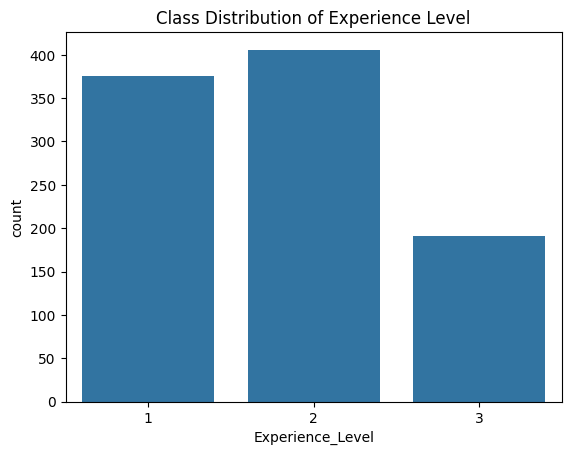

In [9]:
print(df["Experience_Level"].value_counts())  # count of each class
sns.countplot(x="Experience_Level", data=df)  # class distribution plot
plt.title("Class Distribution of Experience Level")  # plot title
plt.show()  # show plot

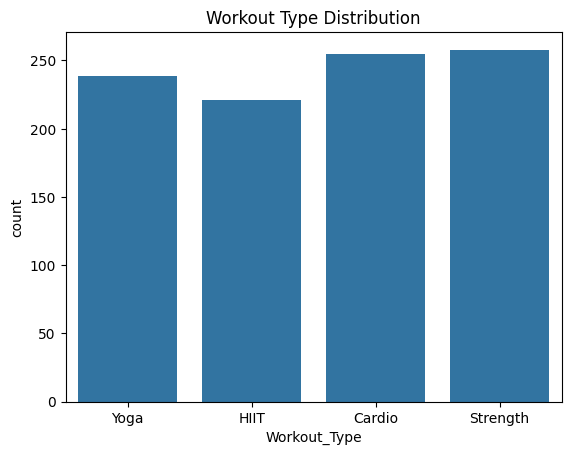

In [10]:
sns.countplot(x="Workout_Type", data=df)  # how many members do each workout type
plt.title("Workout Type Distribution")  # plot title
plt.show()  # show plot

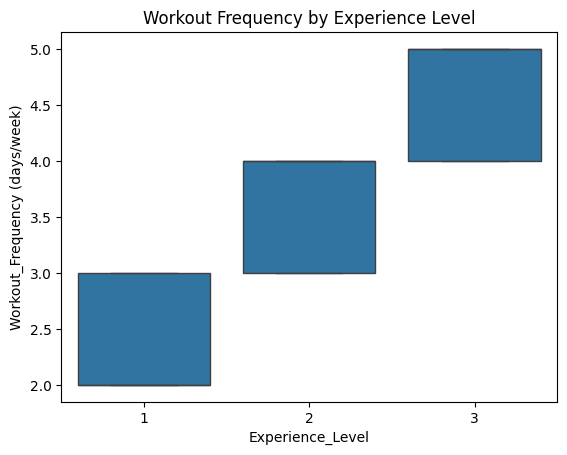

In [11]:
sns.boxplot(x="Experience_Level", y="Workout_Frequency (days/week)", data=df)  # frequency vs experience
plt.title("Workout Frequency by Experience Level")  # plot title
plt.show()  # show plot

## Statistical Study
Significance level used in all tests: **alpha = 0.05**. If p-value < 0.05 we reject the null hypothesis (H0).

### Part B: Relationship Analysis using Covariance and Correlation
- **Covariance:** positive means both variables rise together, negative means one rises as the other falls. Its size depends on the units.
- **Correlation (r):** ranges from -1 to +1. Rough guide: |r| below 0.3 is weak, 0.3 to 0.7 is moderate, above 0.7 is strong.

In [12]:
num_cols = ["Age", "Weight (kg)", "Session_Duration (hours)", "Calories_Burned", "Fat_Percentage", "Water_Intake (liters)", "Workout_Frequency (days/week)"]  # numeric columns to study
print(df[num_cols].cov().round(2))

                                  Age  Weight (kg)  Session_Duration (hours)  \
Age                            148.38        -9.39                     -0.08   
Weight (kg)                     -9.39       449.76                     -0.10   
Session_Duration (hours)        -0.08        -0.10                      0.12   
Calories_Burned               -513.69       551.86                     84.93   
Fat_Percentage                   0.18       -29.94                     -1.25   
Water_Intake (liters)            0.30         5.02                      0.06   
Workout_Frequency (days/week)    0.09        -0.23                      0.20   

                               Calories_Burned  Fat_Percentage  \
Age                                    -513.69            0.18   
Weight (kg)                             551.86          -29.94   
Session_Duration (hours)                 84.93           -1.25   
Calories_Burned                       74333.40        -1019.88   
Fat_Percentage               

                                Age  Weight (kg)  Session_Duration (hours)  \
Age                            1.00        -0.04                     -0.02   
Weight (kg)                   -0.04         1.00                     -0.01   
Session_Duration (hours)      -0.02        -0.01                      1.00   
Calories_Burned               -0.15         0.10                      0.91   
Fat_Percentage                 0.00        -0.23                     -0.58   
Water_Intake (liters)          0.04         0.39                      0.28   
Workout_Frequency (days/week)  0.01        -0.01                      0.64   

                               Calories_Burned  Fat_Percentage  \
Age                                      -0.15            0.00   
Weight (kg)                               0.10           -0.23   
Session_Duration (hours)                  0.91           -0.58   
Calories_Burned                           1.00           -0.60   
Fat_Percentage                           -0.6

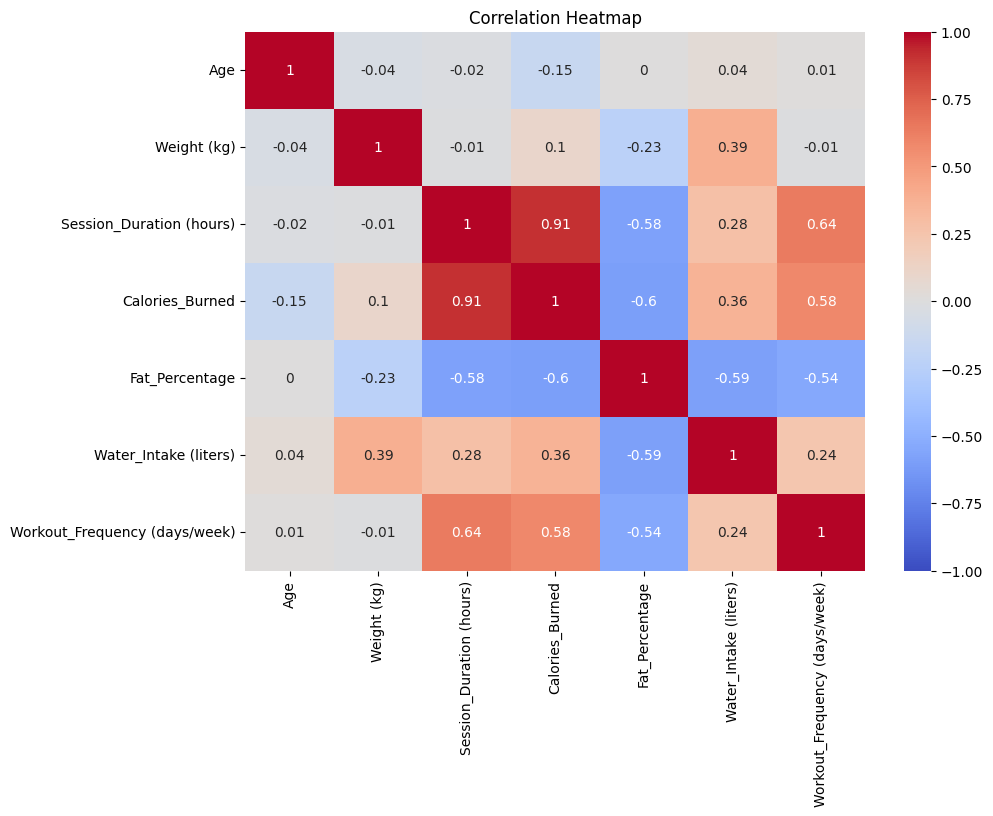

In [13]:
corr = df[num_cols].corr().round(2)  # correlation matrix (shows strength and direction)
print(corr)  # print the matrix
plt.figure(figsize=(10, 7))  # set figure size
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)  # correlation heatmap
plt.title("Correlation Heatmap")  # plot title
plt.show()  # show plot

### Part C: Hypothesis Testing for Correlation (Pearson and Spearman)
- **H0:** there is no correlation between the two variables. **H1:** there is a correlation.
- **Pearson** measures linear relationship. **Spearman** measures rank-based (monotonic) relationship.

In [14]:
pairs = [("Session_Duration (hours)", "Calories_Burned"), ("Workout_Frequency (days/week)", "Fat_Percentage"), ("Water_Intake (liters)", "Workout_Frequency (days/week)"), ("Age", "Calories_Burned")]  # variable pairs to test
for a, b in pairs:  # test one pair at a time
    r, p1 = stats.pearsonr(df[a], df[b])  # Pearson r and p-value
    rho, p2 = stats.spearmanr(df[a], df[b])  # Spearman rho and p-value
    print(a, "vs", b)  # pair name
    print("  Pearson r =", round(r, 3), "| p =", round(p1, 5))  # Pearson result
    print("  Spearman rho =", round(rho, 3), "| p =", round(p2, 5))  # Spearman result
    print("  Decision:", "Reject H0 (significant correlation)" if p1 < 0.05 else "Fail to reject H0 (no significant correlation)")  # compare p with 0.05

Session_Duration (hours) vs Calories_Burned
  Pearson r = 0.908 | p = 0.0
  Spearman rho = 0.903 | p = 0.0
  Decision: Reject H0 (significant correlation)
Workout_Frequency (days/week) vs Fat_Percentage
  Pearson r = -0.537 | p = 0.0
  Spearman rho = -0.444 | p = 0.0
  Decision: Reject H0 (significant correlation)
Water_Intake (liters) vs Workout_Frequency (days/week)
  Pearson r = 0.239 | p = 0.0
  Spearman rho = 0.236 | p = 0.0
  Decision: Reject H0 (significant correlation)
Age vs Calories_Burned
  Pearson r = -0.155 | p = 0.0
  Spearman rho = -0.153 | p = 0.0
  Decision: Reject H0 (significant correlation)


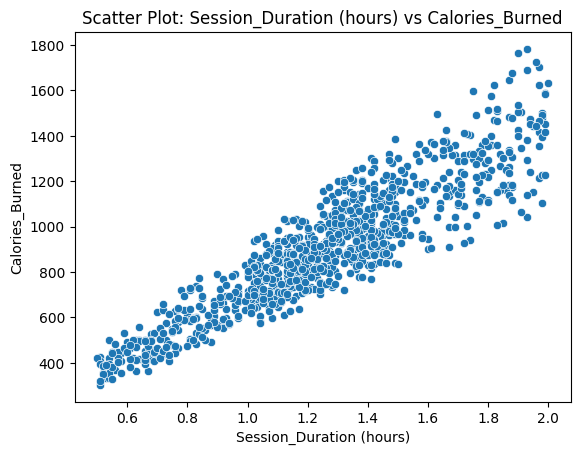

In [15]:
sns.scatterplot(x=pairs[0][0], y=pairs[0][1], data=df)  # scatter plot of the first pair
plt.title("Scatter Plot: " + pairs[0][0] + " vs " + pairs[0][1])  # plot title
plt.show()  # show plot

### Chi-Square Test (relationship between two categorical variables)
**H0:** the two variables are independent. **H1:** they are related.

In [16]:
for a, b in [("Gender", "Workout_Type"), ("Workout_Type", "Experience_Level")]:  # pairs of categorical variables
    table = pd.crosstab(df[a], df[b])  # contingency table
    print(table)  # show the table
    chi2, p, dof, expected = stats.chi2_contingency(table)  # chi-square test
    print(a, "vs", b, "| Chi2 =", round(chi2, 2), "| dof =", dof, "| p =", round(p, 5))  # test result
    print("Decision:", "Related (reject H0)" if p < 0.05 else "Independent (fail to reject H0)")  # compare p with 0.05

Workout_Type  Cardio  HIIT  Strength  Yoga
Gender                                    
Female           126   107       123   106
Male             129   114       135   133
Gender vs Workout_Type | Chi2 = 1.4 | dof = 3 | p = 0.70523
Decision: Independent (fail to reject H0)
Experience_Level    1    2   3
Workout_Type                  
Cardio            109  102  44
HIIT               85   87  49
Strength           97  116  45
Yoga               85  101  53
Workout_Type vs Experience_Level | Chi2 = 5.79 | dof = 6 | p = 0.44708
Decision: Independent (fail to reject H0)


### One-Way ANOVA (compare means of more than two groups)
**H0:** the mean is the same for Beginner, Intermediate and Expert members. **H1:** at least one group mean is different.

In [17]:
print(df.groupby("Experience_Level").mean(numeric_only=True).round(2).T)  # average of each feature per level

Experience_Level                    1       2        3
Age                             38.92   38.65    38.29
Weight (kg)                     73.50   74.38    73.43
Height (m)                       1.73    1.72     1.72
Max_BPM                        180.11  179.46   180.35
Avg_BPM                        143.53  144.23   143.25
Resting_BPM                     62.29   62.07    62.41
Session_Duration (hours)         1.01    1.25     1.76
Calories_Burned                726.38  901.92  1265.34
Fat_Percentage                  27.63   27.31    14.79
Water_Intake (liters)            2.53    2.48     3.12
Workout_Frequency (days/week)    2.48    3.53     4.53
BMI                             24.62   25.26    24.75


In [18]:
cols = ["Workout_Frequency (days/week)", "Session_Duration (hours)", "Calories_Burned", "Fat_Percentage", "Water_Intake (liters)"]  # features to test
for c in cols:  # test one feature at a time
    groups = [df[df["Experience_Level"] == lvl][c] for lvl in [1, 2, 3]]  # values for each level
    f, p = stats.f_oneway(*groups)  # one-way ANOVA
    print(c, "| F =", round(f, 2), "| p =", round(p, 5), "|", "Significant" if p < 0.05 else "Not significant")  # decision

Workout_Frequency (days/week) | F = 1136.76 | p = 0.0 | Significant
Session_Duration (hours) | F = 797.32 | p = 0.0 | Significant
Calories_Burned | F = 503.47 | p = 0.0 | Significant
Fat_Percentage | F = 892.97 | p = 0.0 | Significant
Water_Intake (liters) | F = 98.29 | p = 0.0 | Significant


### Lab 5: Confidence Interval, Z-test and t-test
A confidence interval gives a range in which the true population mean is likely to lie.

In [19]:
x = df["Calories_Burned"]  # variable for the confidence interval
n = len(x)  # sample size
mean = x.mean()  # sample mean
sem = stats.sem(x)  # standard error of the mean
ci95 = stats.t.interval(0.95, n - 1, loc=mean, scale=sem)
ci99 = stats.t.interval(0.99, n - 1, loc=mean, scale=sem)
print("Sample mean =", round(mean, 2))  # show the mean
print("95% CI =", (round(float(ci95[0]), 2), round(float(ci95[1]), 2)))  # show 95% CI
print("99% CI =", (round(float(ci99[0]), 2), round(float(ci99[1]), 2)))  # show 99% CI

Sample mean = 905.42
95% CI = (888.27, 922.57)
99% CI = (882.86, 927.98)


**One-sample Z-test** (large sample, n > 30): H0: mean calories burned = 900. H1: mean is not 900.
The value 900 is an assumed population mean; you can change it.

In [20]:
mu0 = 900  # assumed population mean of calories burned
sigma = x.std()  # sample std used as sigma because the sample is large
z = (mean - mu0) / (sigma / np.sqrt(n))  # z statistic
p_z = 2 * (1 - stats.norm.cdf(abs(z)))  # two-tailed p-value
print("Z =", round(z, 3), "| p =", round(p_z, 5))  # show result
print("Decision:", "Reject H0" if p_z < 0.05 else "Fail to reject H0")  # compare p with 0.05

Z = 0.62 | p = 0.53501
Decision: Fail to reject H0


**One-sample t-test** (small sample, n = 30): H0: mean body fat percentage = 25. H1: mean is not 25.
The value 25 is an assumed population mean; you can change it.

In [21]:
small = df["Fat_Percentage"].sample(30, random_state=42)  # random sample of 30 members
mu1 = 25  # assumed population mean of fat percentage
t_stat, p_t = stats.ttest_1samp(small, mu1)  # one-sample t-test
print("Sample mean =", round(small.mean(), 2))  # show sample mean
print("t =", round(t_stat, 3), "| p =", round(p_t, 5))  # show result
print("Decision:", "Reject H0" if p_t < 0.05 else "Fail to reject H0")  # compare p with 0.05

Sample mean = 24.61
t = -0.402 | p = 0.6904
Decision: Fail to reject H0


### 3.2 Data Preprocessing

In [22]:
df = df.drop_duplicates()  # remove duplicate rows
df = df.dropna()  # remove rows with missing values
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})  # encode gender as numbers
df["Workout_Type"] = df["Workout_Type"].map({"Yoga": 0, "HIIT": 1, "Cardio": 2, "Strength": 3})  # encode workout type
df.head()  # check the encoded data

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,0,88.3,1.71,180,157,60,1.69,1313.0,0,12.6,3.5,4,3,30.20
1,46,1,74.9,1.53,179,151,66,1.30,883.0,1,33.9,2.1,4,2,32.00
2,32,1,68.1,1.66,167,122,54,1.11,677.0,2,33.4,2.3,4,2,24.71
3,25,0,53.2,1.70,190,164,56,0.59,532.0,3,28.8,2.1,3,1,18.41
4,38,0,46.1,1.79,188,158,68,0.64,556.0,3,29.2,2.8,3,1,14.39


In [23]:
X = df.drop("Experience_Level", axis=1)  # input features
y = df["Experience_Level"]  # target variable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # 80-20 split
print("Train:", X_train.shape, "Test:", X_test.shape)  # check split sizes

Train: (778, 14) Test: (195, 14)


### 3.3 Feature Selection

In [24]:
selector = SelectKBest(f_classif, k=6)  # pick the 6 best features
selector.fit(X_train, y_train)  # learn scores on training data only
scores = pd.Series(selector.scores_, index=X_train.columns).sort_values(ascending=False)  # score of each feature
print(scores.round(2))  # print the scores
selected = X_train.columns[selector.get_support()].tolist()  # names of selected features
print("Selected features:", selected)  # show selected features

Workout_Frequency (days/week)    875.50
Fat_Percentage                   727.31
Session_Duration (hours)         623.74
Calories_Burned                  380.00
Water_Intake (liters)             79.29
Height (m)                         2.60
Workout_Type                       1.32
Max_BPM                            0.96
Avg_BPM                            0.91
Resting_BPM                        0.49
Age                                0.41
Weight (kg)                        0.35
BMI                                0.25
Gender                             0.16
dtype: float64
Selected features: ['Height (m)', 'Session_Duration (hours)', 'Calories_Burned', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)']


In [25]:
X_train = X_train[selected]  # keep only selected features in train
X_test = X_test[selected]  # keep only selected features in test
scaler = StandardScaler()  # create the scaler
X_train_s = scaler.fit_transform(X_train)  # fit on train and scale it
X_test_s = scaler.transform(X_test)  # scale test using train values

### 3.4 Training Multiple Classification Models

| Sr. No. | Model Name | Purpose / Notes |
|---|---|---|
| 1 | Logistic Regression | Simple linear baseline |
| 2 | K-Nearest Neighbors | Predicts using the closest similar members |
| 3 | Decision Tree | Easy rule-based model |
| 4 | Random Forest | Many trees combined for better accuracy |

In [26]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),  # model 1
    "KNN": KNeighborsClassifier(n_neighbors=5),  # model 2
    "Decision Tree": DecisionTreeClassifier(random_state=42),  # model 3
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),  # model 4
}
for name, m in models.items():  # train each model
    m.fit(X_train_s, y_train)  # fit on training data
    print(name, "trained")  # confirm training

Logistic Regression trained
KNN trained
Decision Tree trained
Random Forest trained


### 3.5 Performance Evaluation and Model Comparison

In [27]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test_s)
    rows.append({
        "Model": name,  # model name
        "Accuracy": accuracy_score(y_test, pred),  # accuracy
        "Precision": precision_score(y_test, pred, average="weighted"),  # precision
        "Recall": recall_score(y_test, pred, average="weighted"),  # recall
        "F1-Score": f1_score(y_test, pred, average="weighted"),  # F1-score
    })
results = pd.DataFrame(rows).round(4)  # make results table
results  # show comparison table

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8821,0.8835,0.8821,0.8821
1,KNN,0.8564,0.8568,0.8564,0.8562
2,Decision Tree,0.8718,0.8724,0.8718,0.8719
3,Random Forest,0.9026,0.9028,0.9026,0.9024


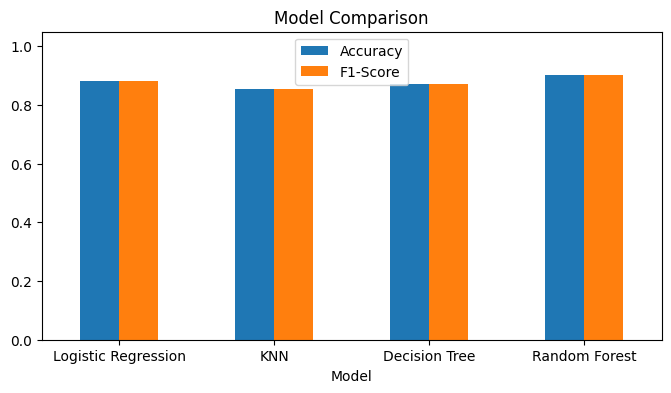

In [28]:
results.set_index("Model")[["Accuracy", "F1-Score"]].plot(kind="bar", figsize=(8, 4))  # compare models
plt.title("Model Comparison")  # plot title
plt.ylim(0, 1.05)  # y axis range
plt.xticks(rotation=0)  # keep labels straight
plt.show()  # show plot

### 3.6 Best Model Selection

In [29]:
best_name = results.sort_values("F1-Score", ascending=False).iloc[0]["Model"]  # model with highest F1
best_model = models[best_name]  # get the best model
print("Best model:", best_name)  # show best model name

Best model: Random Forest


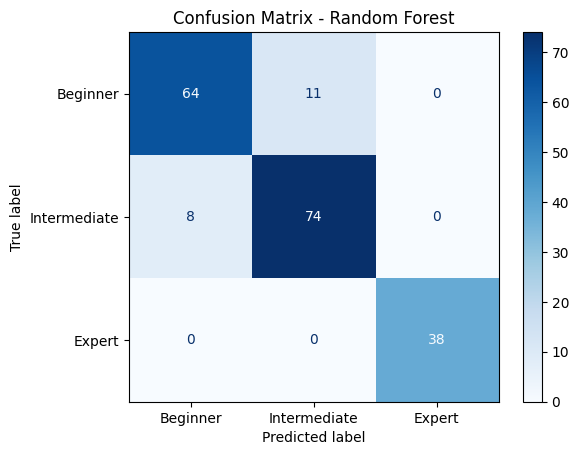

In [30]:
best_pred = best_model.predict(X_test_s)  # predictions of best model
cm = confusion_matrix(y_test, best_pred)  # confusion matrix
ConfusionMatrixDisplay(cm, display_labels=["Beginner", "Intermediate", "Expert"]).plot(cmap="Blues")  # plot matrix
plt.title("Confusion Matrix - " + best_name)  # plot title
plt.show()  # show plot

In [31]:
print(classification_report(y_test, best_pred, target_names=["Beginner", "Intermediate", "Expert"]))  # per-class report

              precision    recall  f1-score   support

    Beginner       0.89      0.85      0.87        75
Intermediate       0.87      0.90      0.89        82
      Expert       1.00      1.00      1.00        38

    accuracy                           0.90       195
   macro avg       0.92      0.92      0.92       195
weighted avg       0.90      0.90      0.90       195



## 4.2 Module-wise Implementation: Save and Load Best Model

In [32]:
joblib.dump({"model": best_model, "scaler": scaler, "features": selected}, "gym_best_model.pkl")  # save model, scaler, features
saved = joblib.load("gym_best_model.pkl")  # load them back
print("Saved and loaded. Features:", saved["features"])  # confirm

Saved and loaded. Features: ['Height (m)', 'Session_Duration (hours)', 'Calories_Burned', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)']


## 4.3 GUI Implementation (Gradio)

In [33]:
labels = {1: "Beginner", 2: "Intermediate", 3: "Expert"}  # class names

def predict(*values):  # function called by the GUI
    data = pd.DataFrame([values], columns=saved["features"])  # put inputs in a dataframe
    data_s = saved["scaler"].transform(data)  # scale the inputs
    probs = saved["model"].predict_proba(data_s)[0]  # probability of each class
    return {labels[c]: float(p) for c, p in zip(saved["model"].classes_, probs)}  # return label probabilities

inputs = [gr.Number(label=c, value=round(float(X_train[c].median()), 2)) for c in saved["features"]]  # one input box per feature

demo = gr.Interface(
    fn=predict,  # prediction function
    inputs=inputs,  # input boxes
    outputs=gr.Label(num_top_classes=3),  # show predicted level
    title="Gym Member Experience Level Predictor",  # GUI title
    description="Enter fitness and lifestyle values to predict the experience level.",  # GUI description
)
demo.launch()  # start the GUI, opens at http://127.0.0.1:7860 (take screenshots here)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2ee4f3786ec88ce110.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
